# 🎓 Computer vision, step by step: EmotionLens
Companion to **[`docs/LEARN.md`](../docs/LEARN.md)**. Each section runs the project's real code and **shows
you the data** at that stage, so nothing is a black box.

```
photo ─► ① pixels ─► ② find faces ─► ③ crop ─► ④ resize+normalize ─► ⑤ model ─► ⑥ probabilities ─► ⑦ why? ─► ⑧ right? ─► ⑨ honest?
```

In [1]:
import torch  # import torch first: on some Macs importing scikit-learn before torch crashes model loading
import sys, json, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
from transformers.utils import logging as hf_logging
hf_logging.set_verbosity_error()             # hide routine library notices
sys.path.insert(0, "..")                      # so `import emotionlens` finds the project package

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from emotionlens import analyze, explain, models

def show(images, titles=None, size=4.5):
    """Draw images side by side."""
    images = images if isinstance(images, list) else [images]
    fig, axes = plt.subplots(1, len(images), figsize=(size * len(images), size))
    for ax, im, t in zip(np.atleast_1d(axes), images, titles or [""] * len(images)):
        ax.imshow(im, cmap="gray" if np.asarray(im).ndim == 2 else None); ax.set_title(t); ax.axis("off")
    plt.tight_layout(); plt.show()

## ① An image is a grid of numbers
We'll use a public-domain NASA crew portrait. `analyze.to_rgb` turns whatever you give it into an RGB array.

shape: (1024, 1280, 3) → (height, width, channels)
dtype: uint8 → whole numbers from 0 to 255
top-left pixel [R, G, B]: [14 13  9]


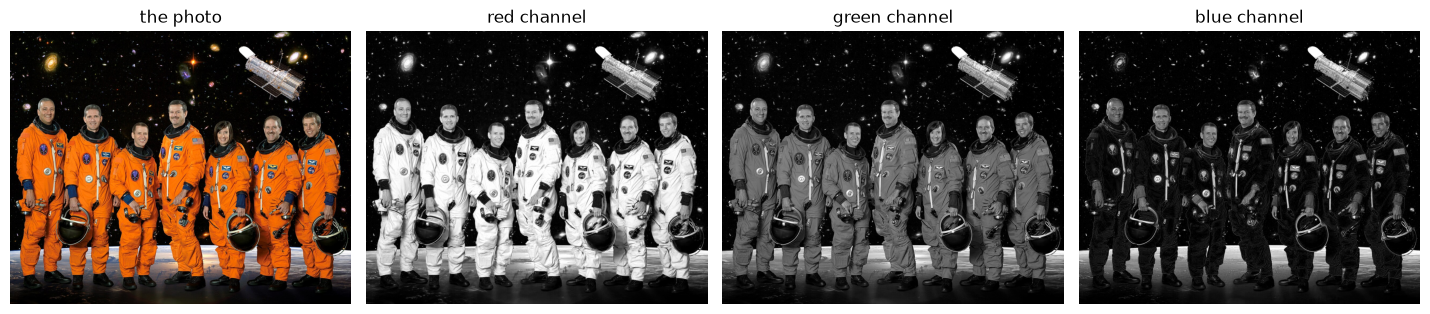

In [2]:
photo = Path("../outputs/sts125_crew.jpg")
if not photo.exists():
    import requests  # urllib can fail on macOS python.org installs until "Install Certificates" is run
    photo.parent.mkdir(exist_ok=True)
    url = "https://upload.wikimedia.org/wikipedia/commons/thumb/9/90/STS-125_crew_portrait.jpg/1280px-STS-125_crew_portrait.jpg"
    # Wikimedia asks scripts to identify themselves with a contact link, or it returns an error page
    r = requests.get(url, headers={"User-Agent": "emotion-lens/0.1 (https://github.com/CohenTheCoder/emotion-lens)"}, timeout=30)
    r.raise_for_status()
    photo.write_bytes(r.content)

rgb = analyze.to_rgb(str(photo))
print("shape:", rgb.shape, "→ (height, width, channels)")
print("dtype:", rgb.dtype, "→ whole numbers from", rgb.min(), "to", rgb.max())
print("top-left pixel [R, G, B]:", rgb[0, 0])
show([rgb, rgb[:, :, 0], rgb[:, :, 1], rgb[:, :, 2]], ["the photo", "red channel", "green channel", "blue channel"], 3.6)

Zoom way in and the "photo" is just a small table of numbers:

red values of the 12×12 patch:
 [[169 157 152 128 103  99 118 119 126 149 167 171]
 [133 135 149 136 124 118 132 120 126 132 145 164]
 [159 183 196 195 202 202 195 184 171 149 141 156]
 [169 212 210 202 204 209 198 211 202 192 168 142]
 [182 212 190 175 170 136 116  99 106 150 160 157]
 [202 179 143 117 102  98  38 120  97  33 103 125]
 [207 115  86  76 103 189  90  77  53  67 141 125]
 [185 132 193 226 183 167 134 135 147 161 147 161]
 [182 205 233 224 207 191 204 209 215 202 176 184]
 [189 214 210 205 213 205 183 189 191 178 193 197]
 [189 207 224 213 193 197 185 198 202 204 202 185]
 [203 215 229 214 207 211 202 194 196 197 195 186]]


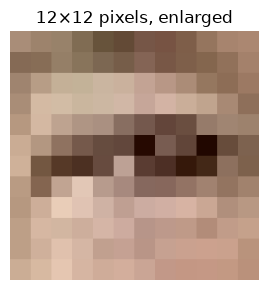

In [3]:
patch = rgb[300:312, 600:612]            # a 12×12 square of pixels
print("red values of the 12×12 patch:\n", patch[:, :, 0])
show([Image.fromarray(patch).resize((240, 240), Image.NEAREST)], ["12×12 pixels, enlarged"], 3)

**Gotcha: BGR vs RGB.** OpenCV stores channels in the opposite order. Mix them up and skin turns blue:

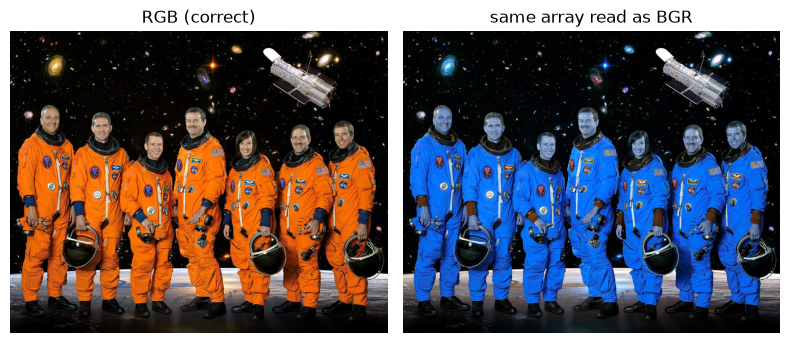

In [4]:
show([rgb, rgb[:, :, ::-1]], ["RGB (correct)", "same array read as BGR"], 4)

## ② Find the faces: object detection with YOLO
The detector returns **bounding boxes** `(x1, y1, x2, y2)` with a **confidence**. The threshold is a knob: too low
lets in false faces (in busier photos), too high misses real ones. In this clean portrait the faces score
0.7–0.9, so watch what happens as the bar rises.

min_conf = 0.05 → 7 faces


min_conf = 0.40 → 7 faces


min_conf = 0.70 → 7 faces
min_conf = 0.80 → 6 faces


min_conf = 0.85 → 3 faces
min_conf = 0.90 → 1 faces


first box (x1, y1, x2, y2), confidence: ((110, 262, 167, 343), 0.7974542379379272)


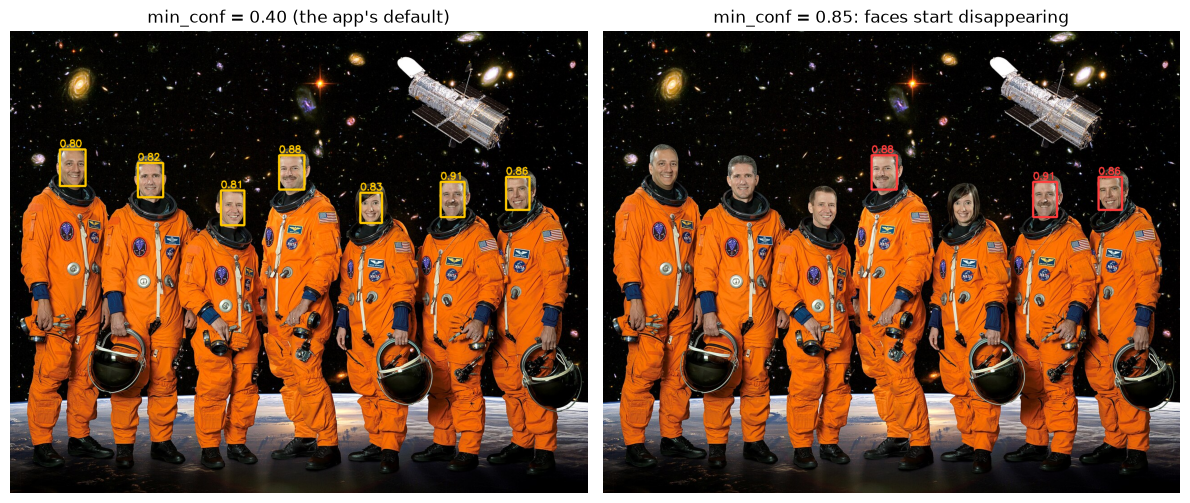

In [5]:
import cv2

def draw_boxes(img, found, color=(255, 200, 0)):
    out = img.copy()
    for (x1, y1, x2, y2), conf in found:
        cv2.rectangle(out, (x1, y1), (x2, y2), color, 3)
        cv2.putText(out, f"{conf:.2f}", (x1, y1 - 6), cv2.FONT_HERSHEY_SIMPLEX, 0.7, color, 2)
    return out

for t in [0.05, 0.4, 0.7, 0.8, 0.85, 0.9]:
    print(f"min_conf = {t:.2f} → {len(analyze.detect_faces(rgb, min_conf=t))} faces")
strict, picky = analyze.detect_faces(rgb, min_conf=0.4), analyze.detect_faces(rgb, min_conf=0.85)
print("first box (x1, y1, x2, y2), confidence:", strict[0])
show([draw_boxes(rgb, strict), draw_boxes(rgb, picky, (255, 60, 60))], ["min_conf = 0.40 (the app's default)", "min_conf = 0.85: faces start disappearing"], 6)

## ③ Crop each face, with a margin
The expression model was trained on loosely framed heads (FER-2013), so we add 20 % around the tight detector
box to make our input look like its training data.

tight crop: (57, 81)   with 20% margin: (79, 113)


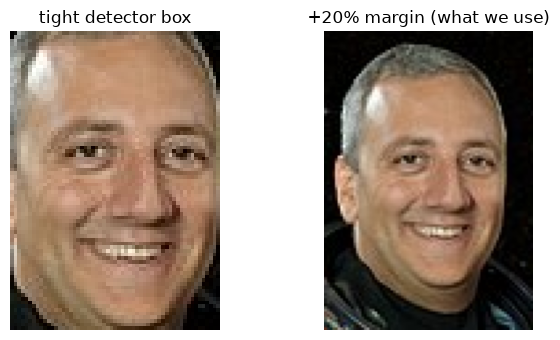

In [6]:
box = strict[0][0]
tight, margin = analyze.crop_face(rgb, box, margin=0.0), analyze.crop_face(rgb, box, margin=0.2)
print("tight crop:", tight.size, "  with 20% margin:", margin.size)
show([tight, margin], ["tight detector box", "+20% margin (what we use)"], 3.5)

## ④ Resize + normalize: speak the model's language
The model's **image processor** resizes to 224×224 and maps 0…255 to roughly −1…1 using `(x/255 − 0.5) / 0.5`.
Note the shape change: `(H, W, 3)` becomes the PyTorch **tensor** `(N, C, H, W)`.

tensor shape: (1, 3, 224, 224) → (batch, channels, height, width)
value range: -1.00 … 1.00   (was 0 … 255)


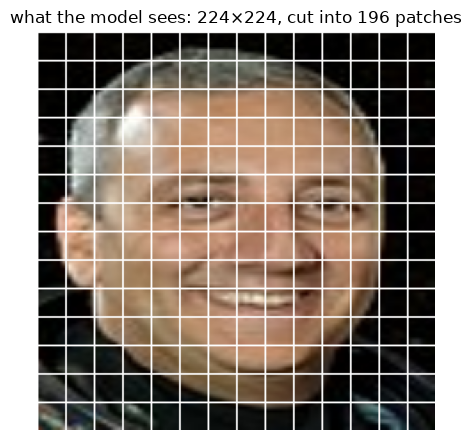

In [7]:
clf = models.expression_classifier()          # downloads/loads the ViT from Hugging Face
batch = clf.image_processor(margin, return_tensors="pt")
x = batch["pixel_values"]
print("tensor shape:", tuple(x.shape), "→ (batch, channels, height, width)")
print(f"value range: {x.min():.2f} … {x.max():.2f}   (was 0 … 255)")

# A Vision Transformer cuts the image into 16×16 patches: 14 × 14 = 196 "words".
view = ((x[0].permute(1, 2, 0).numpy() * 0.5 + 0.5) * 255).astype(np.uint8).copy()
for k in range(0, 224, 16):
    view[k, :] = view[:, k] = (255, 255, 255)
show([view], ["what the model sees: 224×224, cut into 196 patches"], 4.5)

## ⑤ + ⑥ The model: logits → softmax → probabilities
Let's run the model by hand to see the raw **logits**, then apply **softmax** ourselves.

In [8]:
with torch.no_grad():
    logits = clf.model(**batch).logits[0].numpy()
labels = [clf.model.config.id2label[i] for i in range(len(logits))]
probs = np.exp(logits) / np.exp(logits).sum()       # softmax, written out
for l, z, p in sorted(zip(labels, logits, probs), key=lambda t: -t[2]):
    print(f"{l:9s} logit {z:+6.2f}  →  probability {p:6.1%}")
print("sum of probabilities:", probs.sum().round(6))

happy     logit  +6.31  →  probability  99.5%
neutral   logit  +0.03  →  probability   0.2%
surprise  logit  -0.14  →  probability   0.2%
disgust   logit  -1.50  →  probability   0.0%
sad       logit  -1.61  →  probability   0.0%
fear      logit  -1.88  →  probability   0.0%
angry     logit  -1.95  →  probability   0.0%
sum of probabilities: 1.0


Now the full pipeline on every face, the same call the app makes:

face 1: happy    100%
face 2: happy    99%
face 3: happy    100%
face 4: happy    99%
face 5: happy    100%
face 6: happy    99%
face 7: happy    99%


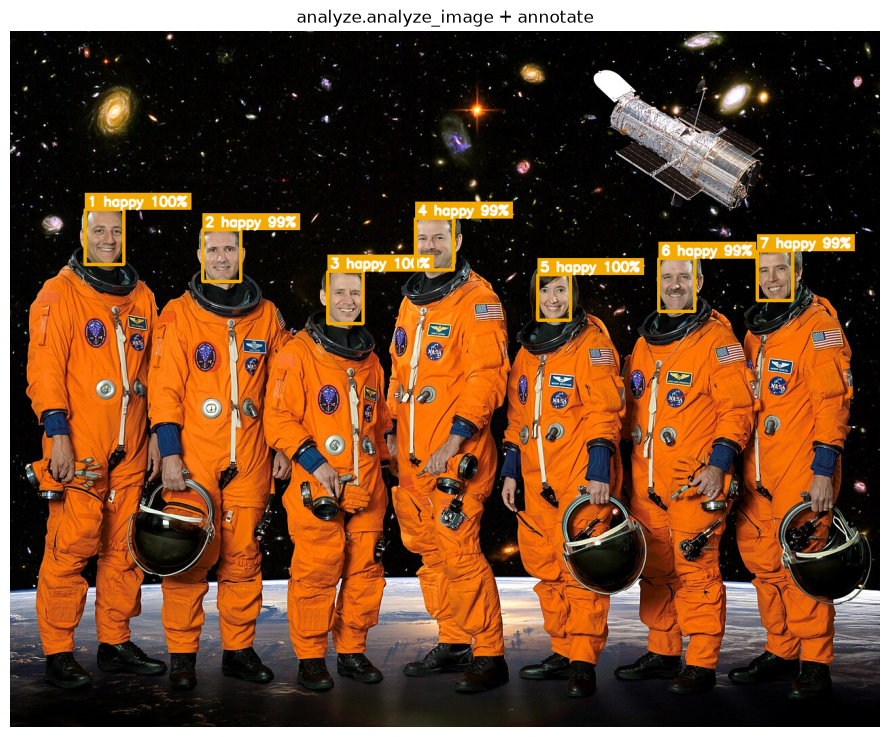

In [9]:
faces, _ = analyze.analyze_image(rgb)
for i, f in enumerate(faces, 1):
    print(f"face {i}: {f.top:8s} {f.confidence:.0%}")
show([analyze.annotate(rgb, faces)], ["analyze.analyze_image + annotate"], 9)

## ⑦ Why did it say that? Occlusion sensitivity
Grey out one patch at a time, re-ask the model, and measure how much the prediction's log-odds **drop**.
Bright areas are the ones the decision depends on.

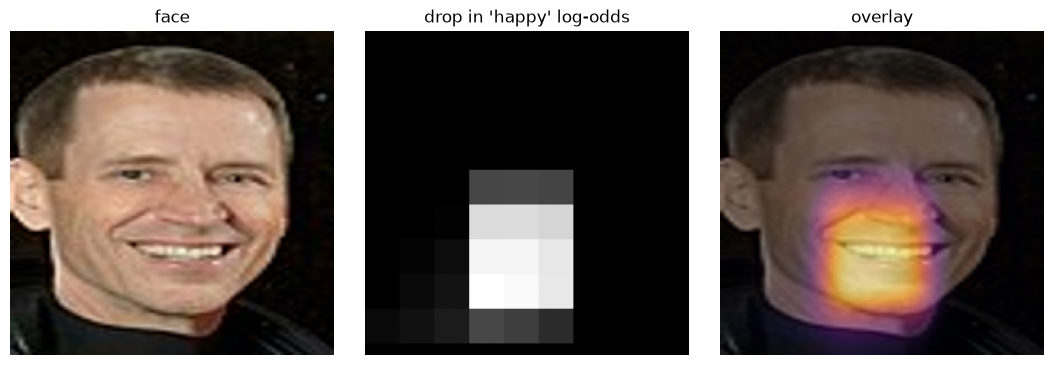

In [10]:
best = max(range(len(faces)), key=lambda i: faces[i].confidence)
face_img = analyze.crop_face(rgb, faces[best].box)
heat = explain.occlusion_map(face_img, faces[best].top)       # 49 extra model calls
show([face_img.resize((224, 224)), heat, explain.overlay(face_img, heat)],
     ["face", f"drop in '{faces[best].top}' log-odds", "overlay"], 3.6)

## ⑧ Is it right? Evaluation on faces it never saw
Precomputed by `python -m emotionlens.evaluate` on FER-2013's **test** split (the model learned from the *train* split).

test faces: 3589
accuracy:  71.8%   vs always-guess-'happy' baseline 24.5%
macro-F1:  0.711


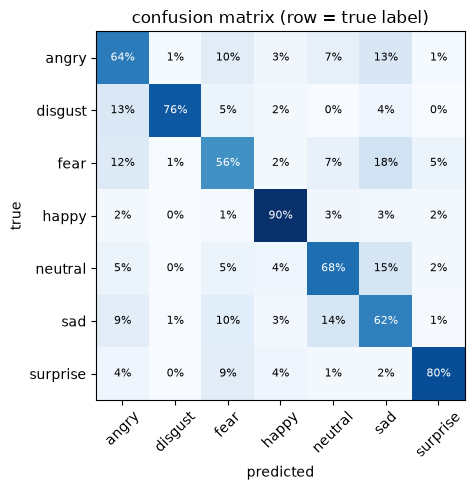

In [11]:
ev = json.load(open("../docs/eval.json"))
print(f"test faces: {ev['n']}")
print(f"accuracy:  {ev['accuracy']:.1%}   vs always-guess-'happy' baseline {ev['majority_baseline']:.1%}")
print(f"macro-F1:  {ev['macro_f1']:.3f}")
cm = np.array(ev["confusion"]); cmn = cm / cm.sum(1, keepdims=True)
fig, ax = plt.subplots(figsize=(6, 5)); ax.imshow(cmn, cmap="Blues")
ax.set_xticks(range(7), ev["labels"], rotation=45); ax.set_yticks(range(7), ev["labels"])
ax.set_xlabel("predicted"); ax.set_ylabel("true")
for i in range(7):
    for j in range(7):
        ax.text(j, i, f"{cmn[i, j]:.0%}", ha="center", va="center", fontsize=8, color="white" if cmn[i, j] > .5 else "black")
ax.set_title("confusion matrix (row = true label)"); plt.tight_layout(); plt.show()

## ⑨ Is it honest? Calibration + temperature scaling
When the model says 90 %, is it right 90 % of the time? Points below the diagonal mean **over-confident**.
Dividing logits by one number **T** (fitted on the *validation* split) fixes it.

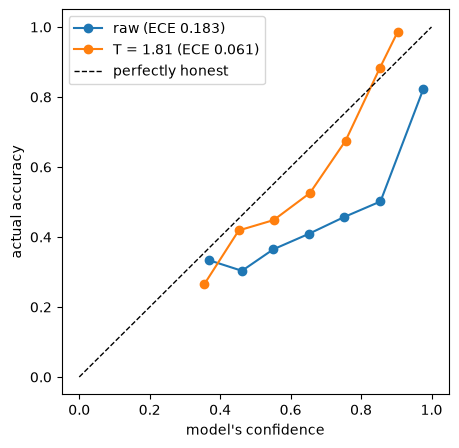

this face: top probability 99.5% raw → 90.4% after temperature scaling (same winner: happy)


In [12]:
fig, ax = plt.subplots(figsize=(5, 5))
for key, name in [("reliability", f"raw (ECE {ev['ece']:.3f})"), ("reliability_calibrated", f"T = {ev['temperature']:.2f} (ECE {ev['ece_calibrated']:.3f})")]:
    pts = [b for b in ev[key] if b["n"] >= 20]
    ax.plot([b["confidence"] for b in pts], [b["accuracy"] for b in pts], "o-", label=name)
ax.plot([0, 1], [0, 1], "k--", lw=1, label="perfectly honest")
ax.set_xlabel("model's confidence"); ax.set_ylabel("actual accuracy"); ax.legend(); plt.show()

T = ev["temperature"]
soft = np.exp(logits / T) / np.exp(logits / T).sum()
print(f"this face: top probability {probs.max():.1%} raw → {soft.max():.1%} after temperature scaling (same winner: {labels[soft.argmax()]})")

## 🎉 You've seen every step
**Next:** run `streamlit run app.py` and try your own photos and video, or try the exercise at the end of
[`docs/LEARN.md`](../docs/LEARN.md): swap in a different model from the Hub and compare accuracy *and* calibration.